# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.**


Устройство: MacBook Pro, Apple M4 Pro, 24 ГБ; PyTorch 2.11.0, MPS.
Режим: FAST_MODE=False, 3 эпохи, seed 0. Выполнены бонусы 6.2–6.5.
Модель: [mBERT](https://huggingface.co/google-bert/bert-base-multilingual-cased), Apache 2.0.
Датасет: [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), русский и английский, CC BY-NC-SA 4.0.
Нерешённых задач в выбранных разделах нет; бонус 6.1 не выбран.

Источники:

- Практики 1–2 (§5.3, §6.3) и 3–4 (§10.4–10.6, §12) курса — режимы обучения, оценка и оптимизация.
- Николенко — «Машинное обучение: основы» (2025), с. 59–60.
- Шаблон ДЗ2, карточки моделей и датасета, документация [Transformers](https://huggingface.co/docs/transformers/main/en/trainer), [datasets](https://huggingface.co/docs/datasets/loading), [PyTorch 2.11](https://docs.pytorch.org/docs/2.11/) и [seqeval](https://github.com/chakki-works/seqeval).


In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1107 20:53:42.142000 34815 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google-bert/bert-base-multilingual-cased
revision: 3f076fdb1ab68d5b2880cb87a0886f315b8146f8
license:  apache-2.0
language: ['multilingual', 'af', 'sq', 'ar', 'an', 'hy', 'ast', 'az', 'ba', 'eu', 'bar', 'be', 'bn', 'inc', 'bs', 'br', 'bg', 'my', 'ca', 'ceb', 'ce', 'zh', 'cv', 'hr', 'cs', 'da', 'nl', 'en', 'et', 'fi', 'fr', 'gl', 'ka', 'de', 'el', 'gu', 'ht', 'he', 'hi', 'hu', 'is', 'io', 'id', 'ga', 'it', 'ja', 'jv', 'kn', 'kk', 'ky', 'ko', 'la', 'lv', 'lt', 'roa', 'nds', 'lm', 'mk', 'mg', 'ms', 'ml', 'mr', 'mn', 'min', 'ne', 'new', 'nb', 'nn', 'oc', 'fa', 'pms', 'pl', 'pt', 'pa', 'ro', 'ru', 'sco', 'sr', 'hr', 'scn', 'sk', 'sl', 'aze', 'es', 'su', 'sw', 'sv', 'tl', 'tg', 'th', 'ta', 'tt', 'te', 'tr', 'uk', 'ud', 'uz', 'vi', 'vo', 'war', 'cy', 'fry', 'pnb', 'yo']
updated:  2024-02-19 11:05:41+00:00
weights:  {'model.safetensors': '681 MB', 'pytorch_model.bin': '681 MB'}
BertTokenizer vocab size 119547
['Петр', 'Ил', '##ьи', '##ч', 'Ч', '##айк', '##овский', 'родился', 'в', 'Во'

**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Выбрала [mBERT](https://huggingface.co/google-bert/bert-base-multilingual-cased) (~177 млн параметров, Apache 2.0), предобученную на Wikipedia на 104 языках, включая русский и английский. Ожидала, что контекст и учёт регистра помогут распознавать сущности после дообучения. Альтернатива — [DistilmBERT](https://huggingface.co/distilbert/distilbert-base-multilingual-cased), те же языки и ~134 млн параметров, по карточке она в среднем вдвое быстрее, но уступает mBERT на XNLI, а качество NER я сравнила в 6.2. Commit hash фиксирует веса, конфиг и токенизатор, без него изменения main могут изменить результаты или сломать повторный запуск.


## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 8677.29it/s]

{'model_type': 'bert', 'vocab_size': 119547, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    encoder = sum(layers)
    head = count(model.classifier)
    total = count(model)

    return {
        'embeddings': embeddings,
        'encoder': encoder,
        'head': head,
        'other': total - embeddings - encoder - head,
        'layers': layers,
    }

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,208,384   52.0%
encoder       85,054,464   48.0%
head               5,383    0.0%
other                  0    0.0%
total        177,268,231
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(
    demo_texts, is_split_into_words=True,
    padding=True, return_tensors='pt'
)

demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
for i, hidden in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]:', tuple(hidden.shape))
print('logits:', tuple(out.logits.shape))

input_ids: (2, 12)
attention_mask: (2, 12)
hidden_states[0]: (2, 12, 768)
hidden_states[1]: (2, 12, 768)
hidden_states[2]: (2, 12, 768)
hidden_states[3]: (2, 12, 768)
hidden_states[4]: (2, 12, 768)
hidden_states[5]: (2, 12, 768)
hidden_states[6]: (2, 12, 768)
hidden_states[7]: (2, 12, 768)
hidden_states[8]: (2, 12, 768)
hidden_states[9]: (2, 12, 768)
hidden_states[10]: (2, 12, 768)
hidden_states[11]: (2, 12, 768)
hidden_states[12]: (2, 12, 768)
logits: (2, 12, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 84.3 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** 

У input_ids и attention_mask форма (2, 12), эмбеддинги дают (2, 12, 768), 12 слоёв энкодера сохраняют эту форму, а голова выдаёт logits (2, 12, 7). Больше всего параметров в эмбеддингах — 92 208 384 (52%) из-за большого многоязычного словаря на 119 547 токенов. Токены обмениваются информацией в энкодере, а эмбеддинги и линейная голова обрабатывают каждую позицию независимо. T больше числа слов из-за разбиения на сабворды, добавления специальных токенов и дополнения короткого предложения padding.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
from datasets import concatenate_datasets

DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'

LABEL_NAMES = [
    'O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG',
    'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC'
]

LANGUAGES = ('ru', 'en')
LIMITS = {'train': 5000, 'validation': 1000, 'test': 1000}
SPLITS = {'train': 'train', 'validation': 'val', 'test': 'test'}

base = (
    f'https://huggingface.co/datasets/{DATASET_ID}'
    f'/resolve/{DATASET_REVISION}/data'
)
data_files = {
    f'{part}_{lang}': f'{base}/{part}_{lang}-00000-of-00001.parquet'
    for lang in LANGUAGES
    for part in SPLITS.values()
}
source = load_dataset('parquet', data_files=data_files)

raw = DatasetDict()
for split, prefix in SPLITS.items():
    parts = []
    for lang in LANGUAGES:
        ds = source[f'{prefix}_{lang}'].shuffle(seed=SEED)
        ds = ds.select(range(min(LIMITS[split], len(ds))))
        ds = ds.select_columns(['tokens', 'ner_tags'])
        ds = ds.add_column('lang', [lang] * len(ds))
        parts.append(ds)

    raw[split] = concatenate_datasets(parts).shuffle(seed=SEED)

print(raw)
ex = raw['train'][0]
print('Язык:', ex['lang'])
print(list(zip(ex['tokens'], [LABEL_NAMES[i] for i in ex['ner_tags']])))

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
})
Язык: ru
[('Помимо', 'O'), ('карательной', 'O'), ('операции', 'O'), ('против', 'O'), ('киргизов', 'B-MISC'), (',', 'O'), ('экспедиция', 'O'), ('в', 'O'), ('горы', 'O'), ('имела', 'O'), ('также', 'O'), ('и', 'O'), ('научные', 'O'), ('цели', 'O'), ('.', 'O')]



train: 10000 предложений
Языки: {'ru': 5000, 'en': 5000}
Сущности: {'LOC': 6770, 'MISC': 3364, 'ORG': 2385, 'PER': 3978}
Предложение, слов: среднее=21.49, медиана=19.0, p95=43.0, максимум=135
Сущность, слов: среднее=1.44, медиана=1.0, p95=3.0, максимум=15

validation: 2000 предложений
Языки: {'en': 1000, 'ru': 1000}
Сущности: {'LOC': 1183, 'MISC': 657, 'ORG': 527, 'PER': 917}
Предложение, слов: среднее=21.37, медиана=20.0, p95=42.0, максимум=107
Сущность, слов: среднее=1.54, медиана=1.0, p95=3.0, максимум=10

test: 2000 предложений
Языки: {'en': 1000, 'ru': 1000}
Сущности: {'LOC': 1344, 'MISC': 686, 'ORG': 554, 'PER': 718}
Предложение, слов: среднее=20.78, медиана=19.0, p95=41.0, максимум=93
Сущность, слов: среднее=1.48, медиана=1.0, p95=3.0, максимум=11


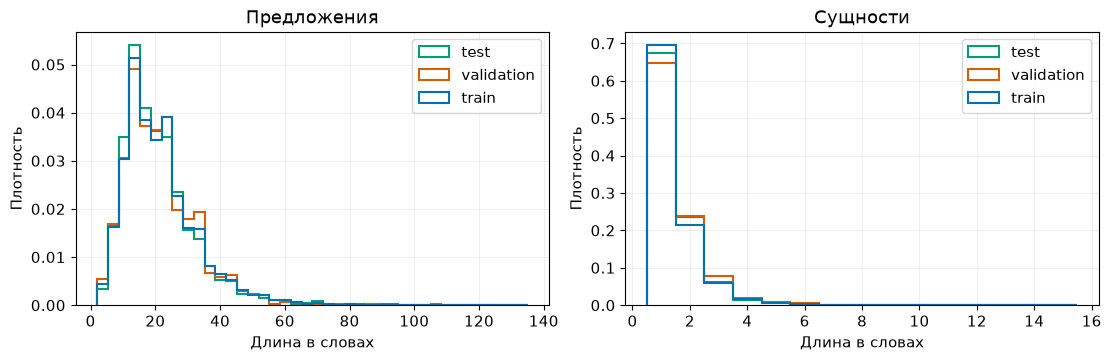

In [14]:
from seqeval.metrics.sequence_labeling import get_entities

entity_types = sorted({tag[2:] for tag in LABEL_NAMES if tag != 'O'})
data_stats = {}

for split, ds in raw.items():
    spans = []
    for ids in ds['ner_tags']:
        spans.extend(get_entities([LABEL_NAMES[i] for i in ids]))

    counts = collections.Counter(kind for kind, _, _ in spans)
    sentence_lengths = [len(tokens) for tokens in ds['tokens']]
    span_lengths = [end - start + 1 for _, start, end in spans]

    data_stats[split] = {
        'entities': counts,
        'sentence_lengths': sentence_lengths,
        'span_lengths': span_lengths,
    }

    print(f'\n{split}: {len(ds)} предложений')
    print('Языки:', dict(collections.Counter(ds['lang'])))
    print('Сущности:', {kind: counts[kind] for kind in entity_types})

    for name, values in [
        ('Предложение', sentence_lengths),
        ('Сущность', span_lengths),
    ]:
        print(
            f'{name}, слов: среднее={np.mean(values):.2f}, '
            f'медиана={np.median(values):.1f}, '
            f'p95={np.percentile(values, 95):.1f}, '
            f'максимум={max(values)}'
        )

fig, axes = plt.subplots(
    1, 2, figsize=(11, 3.5), constrained_layout=True
)

for ax, key, title in zip(
    axes,
    ['sentence_lengths', 'span_lengths'],
    ['Предложения', 'Сущности'],
):
    values = [stats[key] for stats in data_stats.values()]
    bins = (
        40 if key == 'sentence_lengths'
        else np.arange(0.5, max(map(max, values)) + 1.5)
    )
    ax.hist(
        values, bins=bins, density=True, histtype='step',
        linewidth=1.5, label=list(data_stats),
        color=['#0072B2', '#D55E00', '#009E73'],
    )
    ax.set(title=title, xlabel='Длина в словах', ylabel='Плотность')
    ax.legend()
    ax.grid(alpha=0.2)

plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** 

[WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural) содержит тексты Wikipedia с автоматической разметкой на основе BabelNet и нейросетей; лицензия — CC BY-NC-SA 4.0. Взято подмножество из 10 000/2 000/2 000 предложений для train/validation/test, русский и английский представлены поровну.

| Тип | train | validation | test |
|---|---:|---:|---:|
| LOC | 6770 | 1183 | 1344 |
| MISC | 3364 | 657 | 686 |
| ORG | 2385 | 527 | 554 |
| PER | 3978 | 917 | 718 |

Реже всего встречается ORG; медианная длина сущности — 1 слово, предложения — 19–20 слов. Длинные сущности (до 15 слов) усложняют определение границ, длинные предложения (до 135 слов) могут обрезаться при токенизации, а автоматическая разметка может содержать ошибки.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    start, kind = None, None

    for i, tag in enumerate(list(tags) + ['O']):
        prefix, tag_type = (
            ('O', None) if tag == 'O' else tag.split('-', 1)
        )

        if start is not None and (prefix != 'I' or tag_type != kind):
            spans.append((start, i, kind))
            start, kind = None, None

        if prefix in ('B', 'I') and start is None:
            start, kind = i, tag_type

    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words

    for start, end, kind in spans:
        tags[start] = 'B-' + kind
        for i in range(start + 1, end):
            tags[i] = 'I-' + kind

    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels = []
    seen = set()

    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
            continue

        label = word_labels[word_id]
        if word_id in seen:
            label = -100 if b_to_i is None else b_to_i.get(label, label)

        labels.append(label)
        seen.add(word_id)

    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)
roundtrip_changes = {}

for split, ds in raw.items():
    path = DATA_DIR / f'{split}_spans.jsonl'

    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            record = {
                'tokens': ex['tokens'],
                'spans': bio_to_spans(tags),
                'lang': ex['lang'],
            }
            f.write(json.dumps(record, ensure_ascii=False) + '\n')

    with path.open(encoding='utf-8') as f:
        records = [json.loads(line) for line in f]

    assert len(records) == len(ds)
    changed = 0

    for ex, record in zip(ds, records):
        original = [LABEL_NAMES[i] for i in ex['ner_tags']]
        restored = spans_to_bio(record['spans'], len(record['tokens']))

        assert record['tokens'] == ex['tokens']
        assert record['lang'] == ex['lang']
        assert bio_to_spans(restored) == bio_to_spans(original)
        changed += restored != original

    roundtrip_changes[split] = changed
    print(
        f'{split}: проверено {len(ds)}, '
        f'изменился BIO у {changed}; спаны совпали'
    )

train: проверено 10000, изменился BIO у 304; спаны совпали
validation: проверено 2000, изменился BIO у 56; спаны совпали
test: проверено 2000, изменился BIO у 58; спаны совпали


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    if len(enc['input_ids']) == MAX_LENGTH:
        full_ids = tokenizer(
            ex['tokens'], is_split_into_words=True, truncation=False, verbose=False
        )['input_ids']
        n_truncated += len(full_ids) > MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']
train: проверено 9987 предложений, обрезано по MAX_LENGTH 13, слов без сабвордов или за обрезкой 182
[CLS]            None  -100
Помимо              0  O
кара                1  O
##тельной           1  -100
операции            2  O
против              3  O
ки                  4  B-MISC
##рг                4  -100
##из                4  -100
##ов                4  -100
,                   5  O
э                   6  O
##кспедиция         6  -100
в                   7  O
горы                8  O
имела               9  O
также              10  O
и                  11  O
на                 12  O
##учные            12  -100
цели 

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится на первый сабворд, чтобы каждое слово давало один вклад в loss, а -100 исключает остальные сабворды и спецтокены из cross-entropy. В train обрезано 13 из 10000 предложений, 182 слова не представлены после токенизации и обрезки. Если среди пропущенных слов есть сущности, предсказание O для них может снизить recall и F1. При JSON-проверке BIO изменился у 304/56/58 предложений в train/validation/test — I- в начале сущности заменился на B-, при этом все спаны сохранились.


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)

    for words, tags in zip(tokens_list, tags_list):
        for word, tag in zip(words, tags):
            counts[word][tag] += 1

    return {
        word: freq.most_common(1)[0][0]
        for word, freq in counts.items()
    }


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [
    [LABEL_NAMES[i] for i in tags]
    for tags in data['train']['ner_tags']
]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]

baseline = {'majority': entity_scores(val_gold, majority_pred)}

set_seed(SEED)
untrained_model = make_model()
random_pred = predict_word_tags(untrained_model, val_tokens, batch_size=32)
baseline['random_head'] = entity_scores(val_gold, random_pred)
del untrained_model

for name, scores in baseline.items():
    print(name, {key: round(float(value), 4) for key, value in scores.items()})

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 22853.13it/s]


majority {'f1_micro': 0.3376, 'f1_macro': 0.3242, 'precision': 0.4349, 'recall': 0.2759}
random_head {'f1_micro': 0.0193, 'f1_macro': 0.02, 'precision': 0.0108, 'recall': 0.0926}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн дал micro-F1 = 0.3376: повторяющиеся имена помогают, но незнакомые слова получают `O`, а контекст не учитывается, поэтому recall составил 0.2759. Автоматическая разметка WikiNEuRal также может содержать шум, который словарь запоминает. У модели со случайной головой micro-F1 = 0.0193, precision = 0.0108 — почти все предсказанные спаны ошибочны. Энкодер уже формирует языковые представления, но новая голова ещё не обучена сопоставлять их с нашими NER-тегами.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 3e-5
BATCH_SIZE = 16


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR,
              batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer

    for param in model.parameters():
        param.requires_grad_(True)
    if freeze_encoder:
        for param in model.base_model.parameters():
            param.requires_grad_(False)

    total_steps = math.ceil(math.ceil(len(train_ds) / batch_size) * epochs)
    interval = max(1, total_steps // 10)

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        warmup_steps=math.ceil(0.1 * total_steps),
        weight_decay=0.01,
        optim='adamw_torch',
        eval_strategy='steps',
        eval_steps=interval,
        logging_strategy='steps',
        logging_steps=interval,
        logging_first_step=True,
        save_strategy='no',
        report_to='none',
        prediction_loss_only=True,
        fp16=(device.type == 'cuda'),
        use_cpu=(device.type == 'cpu'),
        dataloader_num_workers=0,
        dataloader_pin_memory=(device.type == 'cuda'),
        seed=SEED,
        data_seed=SEED,
        disable_tqdm=True,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        data_collator=DataCollatorForTokenClassification(
            tok, pad_to_multiple_of=32
        ),
        processing_class=tok,
    )

    print('Устройство обучения:', args.device)

    if args.device.type == 'cuda':
        torch.cuda.synchronize()
    elif args.device.type == 'mps':
        torch.mps.synchronize()

    start = time.perf_counter()
    trainer.train()
    trainer.evaluate()

    if args.device.type == 'cuda':
        torch.cuda.synchronize()
    elif args.device.type == 'mps':
        torch.mps.synchronize()

    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 21724.72it/s]


Устройство обучения: mps
{'loss': '2.135', 'grad_norm': '17.01', 'learning_rate': '0', 'epoch': '0.0016'}
{'loss': '0.4549', 'grad_norm': '1.848', 'learning_rate': '2.968e-05', 'epoch': '0.2992'}
{'eval_loss': '0.09171', 'eval_runtime': '7.36', 'eval_samples_per_second': '271.8', 'eval_steps_per_second': '16.98', 'epoch': '0.2992'}
{'loss': '0.07631', 'grad_norm': '1.6', 'learning_rate': '2.671e-05', 'epoch': '0.5984'}
{'eval_loss': '0.05951', 'eval_runtime': '7.633', 'eval_samples_per_second': '262', 'eval_steps_per_second': '16.38', 'epoch': '0.5984'}
{'loss': '0.06293', 'grad_norm': '1.257', 'learning_rate': '2.338e-05', 'epoch': '0.8976'}
{'eval_loss': '0.05223', 'eval_runtime': '7.519', 'eval_samples_per_second': '266', 'eval_steps_per_second': '16.62', 'epoch': '0.8976'}
{'loss': '0.04419', 'grad_norm': '0.6877', 'learning_rate': '2.006e-05', 'epoch': '1.197'}
{'eval_loss': '0.05678', 'eval_runtime': '7.465', 'eval_samples_per_second': '267.9', 'eval_steps_per_second': '16.75', '

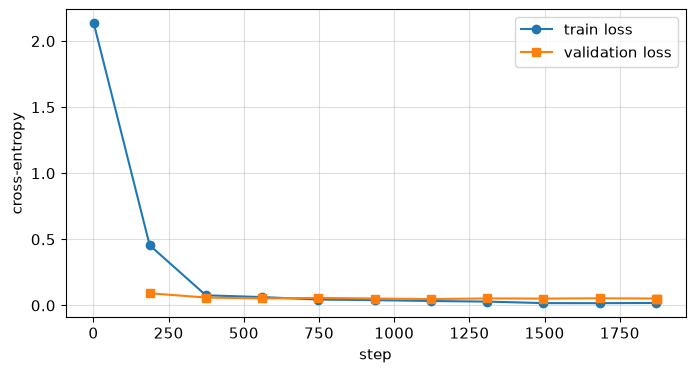

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Взяла LR = 3e-5 для аккуратного дообучения BERT, batch size 16 для умеренного расхода памяти и 3 эпохи как начальный бюджет. Warmup ≈10% даёт плавный старт, weight decay 0.01 — регуляризацию, на MPS использовала FP32. Train loss снизился с 2.135 до 0.01845, а validation loss после 1.8 эпохи не улучшался — минимум 0.04794, в конце 0.05204, что похоже на начало переобучения. Обучение на 10000 предложениях заняло 561.3 с на MPS, поэтому добавлять эпохи пока не стала бы.


## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    correct = n_gold = n_pred = 0

    for gold_tags, pred_tags in zip(gold, pred):
        for true, guess in zip(gold_tags, pred_tags):
            n_gold += true != 'O'
            n_pred += guess != 'O'
            correct += (true == guess and true != 'O')

    denominator = n_gold + n_pred
    return 2 * correct / denominator if denominator else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

eval_results = {}
predictions = {}

for split in ['validation', 'test']:
    tokens = list(data[split]['tokens'])
    gold_tags = [
        [LABEL_NAMES[i] for i in ids]
        for ids in data[split]['ner_tags']
    ]
    pred_tags = predict_word_tags(model, tokens, batch_size=32)
    predictions[split] = pred_tags

    report = classification_report(
        gold_tags, pred_tags, output_dict=True, zero_division=0
    )
    eval_results[split] = {
        **entity_scores(gold_tags, pred_tags),
        'token_f1': token_f1(gold_tags, pred_tags),
        'per_type': {
            kind: report[kind]
            for kind in ENTITY_TYPES if kind in report
        },
        'by_language': {},
    }

    print(f'\n{split}')
    print(classification_report(
        gold_tags, pred_tags, digits=4, zero_division=0
    ))
    print('token_f1:', round(eval_results[split]['token_f1'], 4))

    for lang in LANGUAGES:
        idx = [
            i for i, value in enumerate(data[split]['lang'])
            if value == lang
        ]
        if not idx:
            continue

        lang_scores = entity_scores(
            [gold_tags[i] for i in idx],
            [pred_tags[i] for i in idx],
        )
        eval_results[split]['by_language'][lang] = lang_scores
        print(f'{lang}: F1={lang_scores["f1_micro"]:.4f}, n={len(idx)}')

final = eval_results['test']
val_pred = predictions['validation']


validation
              precision    recall  f1-score   support

         LOC     0.9089    0.9451    0.9266      1183
        MISC     0.8275    0.8326    0.8300       657
         ORG     0.8097    0.8235    0.8166       527
         PER     0.9374    0.9302    0.9338       917

   micro avg     0.8846    0.8989    0.8917      3284
   macro avg     0.8709    0.8828    0.8768      3284
weighted avg     0.8847    0.8989    0.8916      3284

token_f1: 0.9045
ru: F1=0.8852, n=1000
en: F1=0.8980, n=1000

test
              precision    recall  f1-score   support

         LOC     0.9117    0.9375    0.9244      1344
        MISC     0.8034    0.8163    0.8098       686
         ORG     0.8691    0.8628    0.8659       554
         PER     0.9307    0.9359    0.9333       718

   micro avg     0.8863    0.8995    0.8928      3302
   macro avg     0.8788    0.8881    0.8834      3302
weighted avg     0.8862    0.8995    0.8927      3302

token_f1: 0.9075
ru: F1=0.8889, n=1000
en: F1=0.896

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

На test хуже всего распознаётся MISC (F1 = 0.8098), хотя ORG встречается реже — 554 сущности против 686, поэтому одной частотой разницу не объяснить. Вероятно, влияют разнородность MISC, длинные составные названия и шум автоматической разметки. Micro-F1 = 0.8928 выше macro-F1 = 0.8834, поскольку micro сильнее зависит от частых типов, а macro даёт каждому типу одинаковый вес. Токенный F1 = 0.9075 выше сущностного, поскольку засчитывает верные слова и в частично найденном спане, а для пользователя важнее сущностный F1, требующий правильных границ и типа целиком.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    def overlap(a, b):
        return max(a[0], b[0]) < min(a[1], b[1])

    result = []
    for gold in gold_spans:
        candidates = [p for p in pred_spans if overlap(gold, p)]
        same_type = [p for p in candidates if p[2] == gold[2]]
        exact = next(
            (p for p in same_type if p[0] == gold[0] and p[1] == gold[1]),
            None,
        )

        if exact is not None:
            result.append(('correct', gold, exact))
        elif same_type:
            result.append(('boundary', gold, same_type[0]))
        elif candidates:
            result.append(('type', gold, candidates[0]))
        else:
            result.append(('missed', gold, None))

    for pred in pred_spans:
        if not any(overlap(gold, pred) for gold in gold_spans):
            result.append(('spurious', None, pred))

    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter()
examples = {
    category: []
    for category in ERROR_CATEGORIES if category != 'correct'
}

assert len(val_tokens) == len(val_gold) == len(val_pred)

for i, (gold_tags, pred_tags) in enumerate(zip(val_gold, val_pred)):
    assert len(val_tokens[i]) == len(gold_tags) == len(pred_tags)

    rows = categorize_errors(
        bio_to_spans(gold_tags),
        bio_to_spans(pred_tags),
    )
    for category, gold_span, pred_span in rows:
        counts[category] += 1
        if category != 'correct':
            examples[category].append(
                (category, i, gold_span, pred_span)
            )

errors = {category: counts[category] for category in ERROR_CATEGORIES}
n_errors = sum(errors[c] for c in examples)

print('Все категории:', errors)
for category in examples:
    share = errors[category] / n_errors if n_errors else 0.0
    print(f'{category}: {errors[category]} ({share:.1%} ошибок)')

selected = []
for rank in range(6):
    for category in examples:
        if rank < len(examples[category]):
            selected.append(examples[category][rank])


def span_text(span, words):
    if span is None:
        return '—'
    start, end, kind = span
    text = ' '.join(words[start:end])
    return f'{kind} [{start}:{end}] «{text}»'


for number, (category, i, gold_span, pred_span) in enumerate(selected[:6], 1):
    words = val_tokens[i]
    print(f'\n{number}. {category}, предложение {i}')
    print('Текст:', ' '.join(words))
    print('Эталон:', span_text(gold_span, words))
    print('Модель:', span_text(pred_span, words))

Все категории: {'correct': 2952, 'boundary': 78, 'type': 203, 'missed': 51, 'spurious': 86}
boundary: 78 (18.7% ошибок)
type: 203 (48.6% ошибок)
missed: 51 (12.2% ошибок)
spurious: 86 (20.6% ошибок)

1. boundary, предложение 59
Текст: В футбольную секцию « Раднички » его привёл отец .
Эталон: ORG [3:6] «« Раднички »»
Модель: ORG [4:6] «Раднички »»

2. type, предложение 12
Текст: Затянувшаяся осада Ледисмита , Кимберли и Мафекинга сковала основные силы буров , они далее не пытались вести наступательные действия .
Эталон: LOC [4:5] «Кимберли»
Модель: PER [4:5] «Кимберли»

3. missed, предложение 97
Текст: Книга получила премию Хьюго за лучший роман в 2009 году .
Эталон: MISC [2:3] «премию»
Модель: —

4. spurious, предложение 50
Текст: In 2007 – 08 , he was moved from the right wing and played behind Robin van Persie as a withdrawn striker .
Эталон: —
Модель: ORG [2:4] «– 08»

5. boundary, предложение 89
Текст: В том же месяце по версии журнала Business 2.0 он занял 34 место в списке пятид

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Чаще всего встречается type — 203 случая (48.6% ошибок). В примерах границы расходятся на кавычках и части «2.0», типы путаются между LOC/PER и MISC/ORG, пропущено «премию», а лишним спаном стал фрагмент года «– 08». Разметка «Веб» без «2.0» и разделение «премию Хьюго» на две MISC-сущности выглядят сомнительно, включение кавычек в «Раднички» тоже стоит проверить. Чтобы снизить ошибки типа, я бы добавила контекстные примеры для этих пар и проверила согласованность спорной разметки.


## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'

set_seed(SEED)
frozen_model = make_model()

frozen_history, frozen_seconds = train_ner(
    frozen_model,
    tokenized['train'],
    tokenized['validation'],
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    freeze_encoder=True,
    out_dir='runs/freeze',
)

frozen_pred = predict_word_tags(
    frozen_model, val_tokens, batch_size=32
)
RUN_TIMES['train_freeze_sec'] = frozen_seconds

ablation = {
    'setting': ABLATION,
    'split': 'validation',
    'seed': SEED,
    'epochs': EPOCHS,
    'learning_rate': LR,
    'batch_size': BATCH_SIZE,
    'full': {
        **entity_scores(val_gold, val_pred),
        'train_time_sec': RUN_TIMES['train_main_sec'],
        'trainable_params': sum(
            p.numel() for p in model.parameters() if p.requires_grad
        ),
    },
    'freeze': {
        **entity_scores(val_gold, frozen_pred),
        'train_time_sec': frozen_seconds,
        'trainable_params': sum(
            p.numel() for p in frozen_model.parameters() if p.requires_grad
        ),
    },
}

for name in ['full', 'freeze']:
    row = ablation[name]
    print(
        f'{name}: F1={row["f1_micro"]:.4f}, '
        f'время={row["train_time_sec"]:.1f} с, '
        f'обучаемых параметров={row["trainable_params"]:,}'
    )

print('Изменение F1:', round(float(
    ablation['freeze']['f1_micro'] - ablation['full']['f1_micro']
), 4))
print('Ускорение (раз):', round(
    ablation['full']['train_time_sec'] /
    ablation['freeze']['train_time_sec'], 2
))

del frozen_model

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 9496.25it/s]


Устройство обучения: mps
{'loss': '2.135', 'grad_norm': '6.347', 'learning_rate': '0', 'epoch': '0.0016'}
{'loss': '1.919', 'grad_norm': '5.471', 'learning_rate': '2.968e-05', 'epoch': '0.2992'}
{'eval_loss': '1.492', 'eval_runtime': '7.459', 'eval_samples_per_second': '268.1', 'eval_steps_per_second': '16.76', 'epoch': '0.2992'}
{'loss': '1.151', 'grad_norm': '2.32', 'learning_rate': '2.671e-05', 'epoch': '0.5984'}
{'eval_loss': '0.772', 'eval_runtime': '7.639', 'eval_samples_per_second': '261.8', 'eval_steps_per_second': '16.36', 'epoch': '0.5984'}
{'loss': '0.6844', 'grad_norm': '1.193', 'learning_rate': '2.338e-05', 'epoch': '0.8976'}
{'eval_loss': '0.5601', 'eval_runtime': '7.575', 'eval_samples_per_second': '264', 'eval_steps_per_second': '16.5', 'epoch': '0.8976'}
{'loss': '0.5419', 'grad_norm': '0.5941', 'learning_rate': '2.006e-05', 'epoch': '1.197'}
{'eval_loss': '0.5193', 'eval_runtime': '7.249', 'eval_samples_per_second': '275.9', 'eval_steps_per_second': '17.24', 'epoch': 

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

Заморозка снизила validation F1 с 0.8917 до 0.0000 (-0.8917), а время — с 561.3 до 231.2 с, то есть дала ускорение в 2.43 раза. Обучаемых параметров осталось 6921 вместо 177.3 млн, но прямой проход энкодера и валидация всё равно выполняются. Энкодер не адаптировался к NER, а сохранённые LR и число эпох могли не подойти для обучения только головы. Для надёжного вывода я бы повторила сравнение на нескольких seed и отдельно проверила больший LR и число эпох для головы.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

За 3 эпохи дообучения mBERT получила validation F1 = 0.8917 против 0.3376 у словарного бейзлайна и test F1 = 0.8928. На test лучше распознаётся PER (0.9333), хуже MISC (0.8098), а ошибки типа составляют 48.6% ошибок на validation. Английский показал немного больший F1, чем русский — на test 0.8967 против 0.8889, но одного прогона мало для общего вывода. Заморозка энкодера ускорила обучение в 2.43 раза, но снизила validation F1 до нуля при тех же настройках. Ограничения — одна основная модель, один seed, подмножество из 10000/2000/2000 предложений, возможные ошибки автоматической разметки и обрезка до 128 сабвордов. Дальше я бы уточнила спорную разметку, добавила сложные примеры на различение типов и проверила несколько seed и настройки обучения головы.


### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google-bert/bert-base-multilingual-cased", "revision": "3f076fdb1ab68d5b2880cb87a0886f315b8146f8", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 10000, "n_val": 2000, "n_test": 2000, "params_total": 177269769, "ablation": {"setting": "freeze", "split": "validation", "seed": 0, "epochs": 3, "learning_rate": 3e-05, "batch_size": 16, "full": {"f1_micro": 0.8917082011780698, "f1_macro": 0.8767552436314637, "precision": 0.8846269103985616, "recall": 0.8989037758830695, "train_time_sec": 561.3072005840077, "trainable_params": 1772
final F1 micro 0.8928


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [ ]:
if '6.1' in BONUS_TASKS:
    pass


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**


## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    # https://huggingface.co/distilbert/distilbert-base-multilingual-cased (Apache 2.0)
    def compare_encoders():
        alt_id = 'distilbert/distilbert-base-multilingual-cased'
        alt_revision = '45c032ab32cc946ad88a166f7cb282f58c753c2e'
        alt_tokenizer = AutoTokenizer.from_pretrained(
            alt_id, revision=alt_revision, use_fast=True
        )
        assert alt_tokenizer.is_fast
        # DistilBERT не принимает token_type_ids.
        alt_tokenizer.model_input_names = ['input_ids', 'attention_mask']
        alt_data = data.map(
            tokenize_and_align, batched=True,
            fn_kwargs={'tok': alt_tokenizer},
            remove_columns=data['train'].column_names,
        )
        set_seed(SEED)
        alt_model = make_model(alt_id, alt_revision)
        _, alt_seconds = train_ner(
            alt_model, alt_data['train'], alt_data['validation'],
            epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE,
            tok=alt_tokenizer, out_dir='runs/distilmbert',
        )

        bench_words = val_tokens[:16]
        warmup, repeats = 3, 20

        def sync():
            if device.type == 'cuda':
                torch.cuda.synchronize(device)
            elif device.type == 'mps':
                torch.mps.synchronize()

        @torch.inference_mode()
        def benchmark(net, tok):
            net.eval()
            batch = tok(
                bench_words, is_split_into_words=True, truncation=True,
                max_length=MAX_LENGTH, padding='max_length', return_tensors='pt',
            ).to(device)
            for _ in range(warmup):
                net(**batch)
            sync()
            elapsed = []
            for _ in range(repeats):
                start = time.perf_counter()
                net(**batch)
                sync()
                elapsed.append((time.perf_counter() - start) * 1000)
            return {'mean_ms': np.mean(elapsed), 'std_ms': np.std(elapsed)}

        def model_summary(net, tok, model_id, revision, seconds, scores):
            return {
                'model': model_id, 'revision': revision, 'scores': scores,
                'train_time_sec': seconds,
                'params': sum(p.numel() for p in net.parameters()),
                'weights_mib': sum(
                    p.numel() * p.element_size() for p in net.parameters()
                ) / 2**20,
                'forward': benchmark(net, tok),
            }

        alt_scores = {}
        for split in ['validation', 'test']:
            words = list(data[split]['tokens'])
            gold = [[LABEL_NAMES[i] for i in tags] for tags in data[split]['ner_tags']]
            pred = predict_word_tags(alt_model, words, tok=alt_tokenizer, batch_size=32)
            alt_scores[split] = entity_scores(gold, pred)
        results = {
            'mBERT': model_summary(
                model, tokenizer, MODEL_ID, REVISION,
                RUN_TIMES['train_main_sec'], eval_results,
            ),
            'DistilmBERT': model_summary(
                alt_model, alt_tokenizer, alt_id, alt_revision, alt_seconds, alt_scores,
            ),
        }
        for name, row in results.items():
            print(
                f'{name}: val F1={row["scores"]["validation"]["f1_micro"]:.4f}, '
                f'test F1={row["scores"]["test"]["f1_micro"]:.4f}, '
                f'обучение {row["train_time_sec"]:.1f} с, '
                f'forward {row["forward"]["mean_ms"]:.1f} мс, '
                f'{row["params"]:,} параметров, веса {row["weights_mib"]:.1f} МиБ'
            )
        print(f'Замер forward на {device}: {len(bench_words)} × {MAX_LENGTH}, '
              f'{warmup} прогрева, среднее по {repeats} прогонам, без токенизации.')
        return {
            'task': '6.2', 'dataset': DATASET_ID, 'dataset_revision': DATASET_REVISION,
            'seed': SEED, 'epochs': EPOCHS, 'learning_rate': LR,
            'batch_size': BATCH_SIZE, 'max_length': MAX_LENGTH, 'device': str(device),
            'n_by_split': {split: len(data[split]) for split in data},
            'benchmark': {'batch_size': len(bench_words), 'warmup': warmup, 'repeats': repeats},
            'results': results,
        }

    bonus_62 = compare_encoders()
    (ARTIFACTS / 'bonus_6_2.json').write_text(
        json.dumps(json_ready(bonus_62), ensure_ascii=False, indent=2),
        encoding='utf-8',
    )


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 16624.93it/s]


Устройство обучения: mps
{'loss': '2.125', 'grad_norm': '10.36', 'learning_rate': '0', 'epoch': '0.0016'}
{'loss': '0.596', 'grad_norm': '1.578', 'learning_rate': '2.968e-05', 'epoch': '0.2992'}
{'eval_loss': '0.09723', 'eval_runtime': '3.766', 'eval_samples_per_second': '531', 'eval_steps_per_second': '33.19', 'epoch': '0.2992'}
{'loss': '0.08283', 'grad_norm': '1.26', 'learning_rate': '2.671e-05', 'epoch': '0.5984'}
{'eval_loss': '0.06865', 'eval_runtime': '3.964', 'eval_samples_per_second': '504.5', 'eval_steps_per_second': '31.53', 'epoch': '0.5984'}
{'loss': '0.06659', 'grad_norm': '1.482', 'learning_rate': '2.338e-05', 'epoch': '0.8976'}
{'eval_loss': '0.06161', 'eval_runtime': '4.021', 'eval_samples_per_second': '497.4', 'eval_steps_per_second': '31.09', 'epoch': '0.8976'}
{'loss': '0.049', 'grad_norm': '1.066', 'learning_rate': '2.006e-05', 'epoch': '1.197'}
{'eval_loss': '0.05807', 'eval_runtime': '3.88', 'eval_samples_per_second': '515.5', 'eval_steps_per_second': '32.22', 'e

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

В этом прогоне mBERT дала больший test F1 — 0.8928 против 0.8702 у DistilmBERT, но обучалась 561.3 с вместо 326.0 с. На MPS forward для батча 16 × 128 занял 88.6 и 45.1 мс, то есть DistilmBERT быстрее примерно в 1.96 раза, а веса занимают 676.2 и 514.0 МиБ. Данные, сплиты, seed, LR, batch size, число эпох и максимальная длина одинаковые, замеры сделаны на одном устройстве после прогрева. Размер весов характеризует только параметры, пиковую память процесса я не измеряла.


## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    def make_typos(tokens_list, rate=0.15, seed=0):
        if not 0 <= rate <= 1:
            raise ValueError('rate должна быть от 0 до 1')
        rng = random.Random(seed)
        corrupted = []
        for words in tokens_list:
            changed = list(words)
            for pos, word in enumerate(words):
                if len(word) < 4 or not word.isalpha():
                    continue
                positions = [
                    i for i in range(len(word) - 1) if word[i] != word[i + 1]
                ]
                if positions and rng.random() < rate:
                    i = rng.choice(positions)
                    chars = list(word)
                    chars[i], chars[i + 1] = chars[i + 1], chars[i]
                    changed[pos] = ''.join(chars)
            corrupted.append(changed)
        return corrupted

    def tokenization_profile(tokens_list):
        n_words = sum(len(words) for words in tokens_list)
        if n_words == 0:
            return dict(subwords_per_word=0.0, truncated_sentences=0, lost_words=0)
        full = tokenizer(
            tokens_list, is_split_into_words=True, truncation=False, verbose=False
        )
        cropped = tokenizer(
            tokens_list, is_split_into_words=True,
            truncation=True, max_length=MAX_LENGTH,
        )
        n_subwords = sum(
            sum(word_id is not None for word_id in full.word_ids(i))
            for i in range(len(tokens_list))
        )
        lost_words = sum(
            len(words) - len(set(cropped.word_ids(i)) - {None})
            for i, words in enumerate(tokens_list)
        )
        return {
            'subwords_per_word': n_subwords / n_words,
            'truncated_sentences': sum(
                len(ids) > MAX_LENGTH for ids in full['input_ids']
            ),
            'lost_words': lost_words,
        }

    assert len(val_tokens) == len(val_gold) == len(data['validation'])
    robustness_cases = {
        'original': [list(words) for words in val_tokens],
        'lower': [[word.lower() for word in words] for words in val_tokens],
        'upper': [[word.upper() for word in words] for words in val_tokens],
        'typos': make_typos(val_tokens, rate=0.15, seed=SEED),
    }
    language_indices = {
        lang: [
            i for i, value in enumerate(data['validation']['lang']) if value == lang
        ]
        for lang in LANGUAGES
    }
    robustness_results = {}
    clean_f1 = None

    for case_name, case_tokens in robustness_cases.items():
        assert all(
            len(words) == len(tags) for words, tags in zip(case_tokens, val_gold)
        )
        case_pred = predict_word_tags(model, case_tokens, batch_size=32)
        scores = entity_scores(val_gold, case_pred)
        if case_name == 'original':
            clean_f1 = scores['f1_micro']
        scores['delta_f1'] = scores['f1_micro'] - clean_f1
        scores.update(tokenization_profile(case_tokens))
        scores['changed_words'] = sum(
            old_word != new_word
            for old, new in zip(val_tokens, case_tokens)
            for old_word, new_word in zip(old, new)
        )
        scores['by_language'] = {}
        for lang, idx in language_indices.items():
            if idx:
                scores['by_language'][lang] = entity_scores(
                    [val_gold[i] for i in idx], [case_pred[i] for i in idx]
                )
        robustness_results[case_name] = scores
        print(
            f'{case_name}: F1={scores["f1_micro"]:.4f}, '
            f'ΔF1={scores["delta_f1"]:+.4f}, '
            f'сабвордов/слово={scores["subwords_per_word"]:.2f}, '
            f'обрезано={scores["truncated_sentences"]}, '
            f'потеряно слов={scores["lost_words"]}, '
            f'изменено слов={scores["changed_words"]}'
        )

    bonus_63 = {
        'task': '6.3',
        'model': MODEL_ID,
        'revision': REVISION,
        'dataset': DATASET_ID,
        'dataset_revision': DATASET_REVISION,
        'split': 'validation',
        'n_sentences': len(val_tokens),
        'seed': SEED,
        'max_length': MAX_LENGTH,
        'typo_rate': 0.15,
        'typo_rule': (
            'Перестановка соседних разных букв с вероятностью 0.15 '
            'для слов из букв длиной не менее 4 символов'
        ),
        'results': robustness_results,
    }
    bonus_path = ARTIFACTS / 'bonus_6_3.json'
    bonus_path.write_text(
        json.dumps(json_ready(bonus_63), ensure_ascii=False, indent=2),
        encoding='utf-8',
    )
    print('Сохранено:', bonus_path)


original: F1=0.8917, ΔF1=+0.0000, сабвордов/слово=1.43, обрезано=3, потеряно слов=49, изменено слов=0
lower: F1=0.2644, ΔF1=-0.6273, сабвордов/слово=1.46, обрезано=3, потеряно слов=51, изменено слов=6866
upper: F1=0.1816, ΔF1=-0.7102, сабвордов/слово=3.44, обрезано=209, потеряно слов=2039, изменено слов=34056
typos: F1=0.8617, ΔF1=-0.0300, сабвордов/слово=1.54, обрезано=5, потеряно слов=72, изменено слов=3403
Сохранено: artifacts/bonus_6_3.json


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Сильнее всего повлиял верхний регистр — F1 упал с 0.8917 до 0.1816, тогда как нижний регистр дал 0.2644, а опечатки — 0.8617. При upper число сабвордов на слово выросло с 1.43 до 3.44, обрезанных предложений — с 3 до 209, потерянных слов — с 49 до 2039. Вероятно, у cased-модели одновременно нарушаются привычные признаки регистра и сильно меняется токенизация, а обрезка дополнительно уменьшает доступный контекст. Опечатки затронули 3403 слова и снизили F1 на 0.0300 в этом эксперименте.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    def run_quantization_benchmark():
        import platform
        import tempfile

        cpu = torch.device('cpu')
        warmup_runs, timed_runs = 3, 15
        eval_batch_size = 32
        # Первые восемь примеров из уже перемешанного validation.
        bench_tokens = val_tokens[:8]
        bench_batch = tokenizer(
            bench_tokens, is_split_into_words=True, truncation=True,
            max_length=MAX_LENGTH, padding=True, return_tensors='pt',
        ).to(cpu)

        @torch.inference_mode()
        def latency_ms(net):
            for _ in range(warmup_runs):
                net(**bench_batch)
            start = time.perf_counter()
            for _ in range(timed_runs):
                net(**bench_batch)
            return (time.perf_counter() - start) * 1000 / timed_runs

        def quality_and_size(net):
            predictions = predict_word_tags(
                net, val_tokens, dev=cpu, batch_size=eval_batch_size,
            )
            with tempfile.TemporaryFile() as checkpoint:
                torch.save(net.state_dict(), checkpoint)
                size_bytes = checkpoint.tell()
            return {
                'f1_micro': entity_scores(val_gold, predictions)['f1_micro'],
                'state_dict_bytes': size_bytes,
            }

        previous_engine = torch.backends.quantized.engine
        available_engines = torch.backends.quantized.supported_engines
        engine = next((name for name in (previous_engine, 'x86', 'fbgemm', 'qnnpack', 'onednn')
                       if name != 'none' and name in available_engines), None)
        if engine is None:
            raise RuntimeError('PyTorch не предоставляет CPU-бэкенд для INT8')

        # CPU-копия сохраняет дообученную модель на исходном устройстве.
        cpu_model = copy.deepcopy(model).cpu().float().eval()
        embedding_params = sum(
            layer.weight.numel() for layer in cpu_model.modules()
            if isinstance(layer, torch.nn.Embedding)
        )
        total_params = sum(param.numel() for param in cpu_model.parameters())

        fp32 = quality_and_size(cpu_model)
        fp32['latency_ms'] = latency_ms(cpu_model)
        try:
            torch.backends.quantized.engine = engine
            # Источник: https://docs.pytorch.org/docs/2.11/generated/torch.ao.quantization.quantize_dynamic.html
            torch.ao.quantization.quantize_dynamic(
                cpu_model, {torch.nn.Linear}, dtype=torch.qint8, inplace=True,
            )
            quantized_layers = sum(
                isinstance(layer, torch.ao.nn.quantized.dynamic.Linear)
                for layer in cpu_model.modules()
            )
            assert quantized_layers > 0, 'Нет квантизованных линейных слоёв'
            int8_latency = latency_ms(cpu_model)
            int8 = quality_and_size(cpu_model)
            int8['latency_ms'] = int8_latency
        finally:
            # Некоторые сборки начинают с 'none', но не разрешают выбрать его снова.
            if previous_engine in available_engines and previous_engine != engine:
                torch.backends.quantized.engine = previous_engine

        return {
            'task': '6.4', 'model': MODEL_ID, 'revision': REVISION,
            'dataset': DATASET_ID, 'dataset_revision': DATASET_REVISION,
            'split': 'validation', 'n_sentences': len(val_tokens), 'seed': SEED,
            'method': 'dynamic int8 Linear', 'quantized_engine': engine,
            'previous_quantized_engine': previous_engine,
            'quantized_engine_after': torch.backends.quantized.engine,
            'quantized_linear_layers': quantized_layers,
            'device': cpu.type, 'architecture': platform.machine(),
            'torch_version': str(torch.__version__), 'cpu_threads': torch.get_num_threads(),
            'bench_shape': list(bench_batch['input_ids'].shape),
            'warmup_runs': warmup_runs, 'timed_runs': timed_runs,
            'eval_batch_size': eval_batch_size, 'max_length': MAX_LENGTH,
            'embedding_parameter_fraction': embedding_params / total_params,
            'results': {'fp32': fp32, 'int8': int8},
            'speedup': fp32['latency_ms'] / int8['latency_ms'],
            'delta_f1': int8['f1_micro'] - fp32['f1_micro'],
        }

    bonus_64 = run_quantization_benchmark()
    batch_size_64, seq_len_64 = bonus_64['bench_shape']
    print(
        f'CPU {bonus_64["architecture"]}, {bonus_64["cpu_threads"]} потоков, '
        f'{bonus_64["quantized_engine"]}, батч {batch_size_64} × {seq_len_64}, '
        f'{bonus_64["warmup_runs"]} прогрева и {bonus_64["timed_runs"]} замеров'
    )
    if bonus_64['quantized_engine_after'] != bonus_64['previous_quantized_engine']:
        print(f'CPU-бэкенд сессии установлен в {bonus_64["quantized_engine_after"]}.')
    for variant_64, row_64 in bonus_64['results'].items():
        print(
            f'{variant_64}: {row_64["latency_ms"]:.2f} мс/батч, '
            f'F1={row_64["f1_micro"]:.4f}, '
            f'размер state_dict={row_64["state_dict_bytes"] / 2**20:.1f} МиБ'
        )
    print(
        f'FP32/INT8 по задержке: {bonus_64["speedup"]:.2f}×, '
        f'ΔF1={bonus_64["delta_f1"]:+.4f}. '
        f'Доля параметров в эмбеддингах: {bonus_64["embedding_parameter_fraction"]:.1%}'
    )
    bonus_path = ARTIFACTS / 'bonus_6_4.json'
    bonus_path.write_text(
        json.dumps(json_ready(bonus_64), ensure_ascii=False, indent=2),
        encoding='utf-8',
    )
    print('Сохранено:', bonus_path)


4142971219.py:57: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.quantize_dynamic(
[W1107 21:21:30.152592000 qlinear_dynamic.cpp:251] Warning: Currently, qnnpack incorrectly ignores reduce_range when it is set to true; this may change in a future release. (function operator())


CPU arm64, 8 потоков, qnnpack, батч 8 × 59, 3 прогрева и 15 замеров
CPU-бэкенд сессии установлен в qnnpack.
fp32: 45.09 мс/батч, F1=0.8917, размер state_dict=676.3 МиБ
int8: 150.55 мс/батч, F1=0.8892, размер state_dict=433.3 МиБ
FP32/INT8 по задержке: 0.30×, ΔF1=-0.0026. Доля параметров в эмбеддингах: 52.0%
Сохранено: artifacts/bonus_6_4.json


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На CPU arm64 с 8 потоками INT8-квантизация замедлила обработку батча 8 × 59 с 45.09 до 150.55 мс, то есть примерно в 3.34 раза. Validation F1 изменился с 0.8917 до 0.8892 (-0.0026), размер state_dict уменьшился с 676.3 до 433.3 МиБ. INT8 применён к 73 линейным слоям, а эмбеддинги с 52% параметров остались FP32. Время зависит от вычислений линейных слоёв энкодера и реализации бэкенда, в данном случае затраты на динамическую квантизацию и QNNPACK на небольшом батче могли перевесить выигрыш от INT8.


## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

Порог 0 — P=0.8846, R=0.8989, F1=0.8917
mean — порог 0.6300123780965805, P=0.9068, R=0.8855, F1=0.8960, ΔF1=+0.0043
min — порог 0.632087767124176, P=0.9116, R=0.8791, F1=0.8951, ΔF1=+0.0033


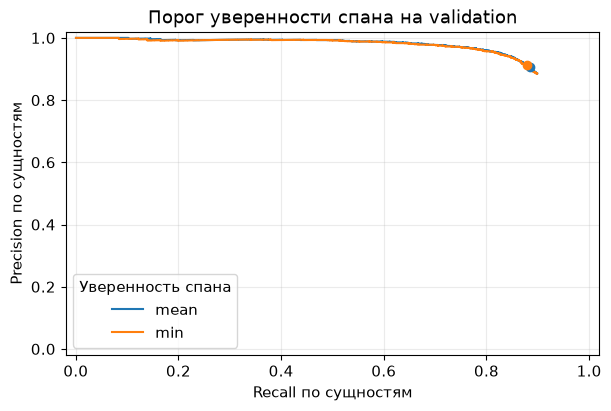

Сохранено artifacts/bonus_6_5.json


In [34]:
if '6.5' in BONUS_TASKS:
    def run_bonus_65():
        pred_tags, word_probs = predict_word_tags(
            model, val_tokens, batch_size=32, return_probs=True,
        )
        score_groups = {
            'mean': collections.defaultdict(collections.Counter),
            'min': collections.defaultdict(collections.Counter),
        }
        n_gold = 0
        for gold_tags, tags, probs in zip(val_gold, pred_tags, word_probs):
            gold_spans = set(bio_to_spans(gold_tags))
            n_gold += len(gold_spans)
            for span in bio_to_spans(tags):
                start, end, _ = span
                span_probs = probs[start:end]
                confidences = {
                    'mean': sum(span_probs) / len(span_probs), 'min': min(span_probs),
                }
                for method, confidence in confidences.items():
                    counts = score_groups[method][confidence]
                    counts['predicted'] += 1
                    counts['tp'] += span in gold_spans

        result = {
            'task': '6.5',
            'model': MODEL_ID,
            'revision': REVISION,
            'dataset': DATASET_ID,
            'dataset_revision': DATASET_REVISION,
            'split': 'validation',
            'n_sentences': len(val_tokens),
            'n_gold': n_gold,
            'methods': {},
        }
        fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
        for method, groups in score_groups.items():
            n_pred = n_correct = 0
            curve = []
            # При снижении порога одновременно добавляются все спаны с этим score.
            for threshold in sorted(set(groups) | {0.0, 1.0}, reverse=True):
                counts = groups.get(threshold, {})
                n_pred += counts.get('predicted', 0)
                n_correct += counts.get('tp', 0)
                total = n_pred + n_gold
                curve.append({
                    'threshold': threshold,
                    'precision': n_correct / n_pred if n_pred else 0.0,
                    'recall': n_correct / n_gold if n_gold else 0.0,
                    'f1_micro': 2 * n_correct / total if total else 0.0,
                    'n_pred': n_pred,
                    'tp': n_correct,
                })

            baseline = curve[-1]
            # При одинаковом F1 выбираем меньший порог.
            best = max(curve, key=lambda point: (point['f1_micro'], -point['threshold']))
            result['methods'][method] = {
                'best': best,
                'delta_f1': best['f1_micro'] - baseline['f1_micro'],
            }
            plot_points = [point for point in curve if point['n_pred']] or [baseline]
            line, = ax.plot(
                [point['recall'] for point in plot_points],
                [point['precision'] for point in plot_points],
                drawstyle='steps-post', label=method,
            )
            ax.scatter(best['recall'], best['precision'], color=line.get_color(), zorder=3)

        result['baseline'] = baseline
        print(
            f'Порог 0 — P={baseline["precision"]:.4f}, R={baseline["recall"]:.4f}, '
            f'F1={baseline["f1_micro"]:.4f}'
        )
        for method, summary in result['methods'].items():
            best = summary['best']
            print(
                f'{method} — порог {best["threshold"]}, '
                f'P={best["precision"]:.4f}, R={best["recall"]:.4f}, '
                f'F1={best["f1_micro"]:.4f}, ΔF1={summary["delta_f1"]:+.4f}'
            )

        ax.set(
            xlabel='Recall по сущностям', ylabel='Precision по сущностям',
            title='Порог уверенности спана на validation',
            xlim=(-0.02, 1.02), ylim=(-0.02, 1.02),
        )
        ax.legend(title='Уверенность спана')
        ax.grid(alpha=0.25)
        plt.show()
        plt.close(fig)

        bonus_path = ARTIFACTS / 'bonus_6_5.json'
        bonus_path.write_text(
            json.dumps(json_ready(result), ensure_ascii=False, indent=2), encoding='utf-8',
        )
        print('Сохранено', bonus_path)

    run_bonus_65()


**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Для средней уверенности лучший порог ≈0.6300 дал validation F1 = 0.8960, прирост к порогу 0 составил 0.0043. Для минимальной уверенности лучший порог ≈0.6321 дал F1 = 0.8951, прирост 0.0033. Средняя уверенность сглаживает одно неуверенное слово, а минимальная сильнее реагирует на него, в этом прогоне у min precision выше (0.9116 против 0.9068), а recall ниже (0.8791 против 0.8855). Recall не может вырасти, поскольку фильтрация только удаляет готовые спаны и не добавляет новых верных сущностей.
